In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("MindMap AI - Libraries imported successfully!")


MindMap AI - Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (8).zip to archive (8) (1).zip


In [4]:

import io
import zipfile
import pandas as pd

# Read your uploaded ZIP file
file_name = next(iter(uploaded))
zip_data = uploaded[file_name]

# Open ZIP and find CSV files
with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    print("CSV files found:", csv_files)

    # Read the first CSV file
    if not csv_files:
        raise ValueError("No CSV file found inside ZIP!")

    with z.open(csv_files[0]) as f:
        df = pd.read_csv(f)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


CSV files found: ['xAPI-Edu-Data.csv']

Dataset loaded successfully!
Dataset Shape: (480, 17)


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M



Column Names:
['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID', 'SectionID', 'Topic', 'Semester', 'Relation', 'raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion', 'ParentAnsweringSurvey', 'ParentschoolSatisfaction', 'StudentAbsenceDays', 'Class']


In [5]:

# 1. Check dataset size
print("Dataset Shape:", df.shape)

# 2. Check column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. View dataset information
print("\nDataset Information:")
df.info()


Dataset Shape: (480, 17)

Columns:
['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID', 'SectionID', 'Topic', 'Semester', 'Relation', 'raisedhands', 'VisITedResources', 'AnnouncementsView', 'Discussion', 'ParentAnsweringSurvey', 'ParentschoolSatisfaction', 'StudentAbsenceDays', 'Class']

Data Types:
gender                      object
NationalITy                 object
PlaceofBirth                object
StageID                     object
GradeID                     object
SectionID                   object
Topic                       object
Semester                    object
Relation                    object
raisedhands                  int64
VisITedResources             int64
AnnouncementsView            int64
Discussion                   int64
ParentAnsweringSurvey       object
ParentschoolSatisfaction    object
StudentAbsenceDays          object
Class                       object
dtype: object

Missing Values:
gender                      0
NationalITy                 0
Pl

In [6]:

# Create a cleaned copy
data = df.copy()

# Remove duplicate records
data = data.drop_duplicates().copy()

# Remove leading/trailing spaces in column names
data.columns = data.columns.str.strip()

# Clean text columns
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()

print("Original Shape:", df.shape)
print("Cleaned Shape:", data.shape)
print("\nMissing Values:")
print(data.isnull().sum().sum())

display(data.head())


Original Shape: (480, 17)
Cleaned Shape: (478, 17)

Missing Values:
0


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


Class
M    211
H    142
L    125
Name: count, dtype: int64


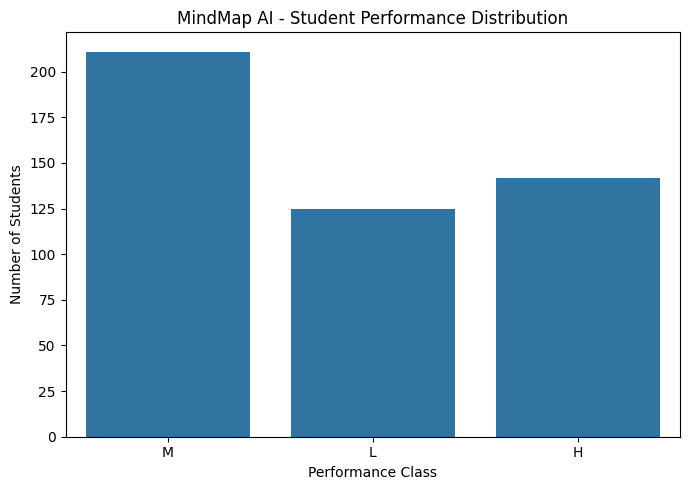

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Performance distribution
print(data["Class"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="Class")
plt.title("MindMap AI - Student Performance Distribution")
plt.xlabel("Performance Class")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


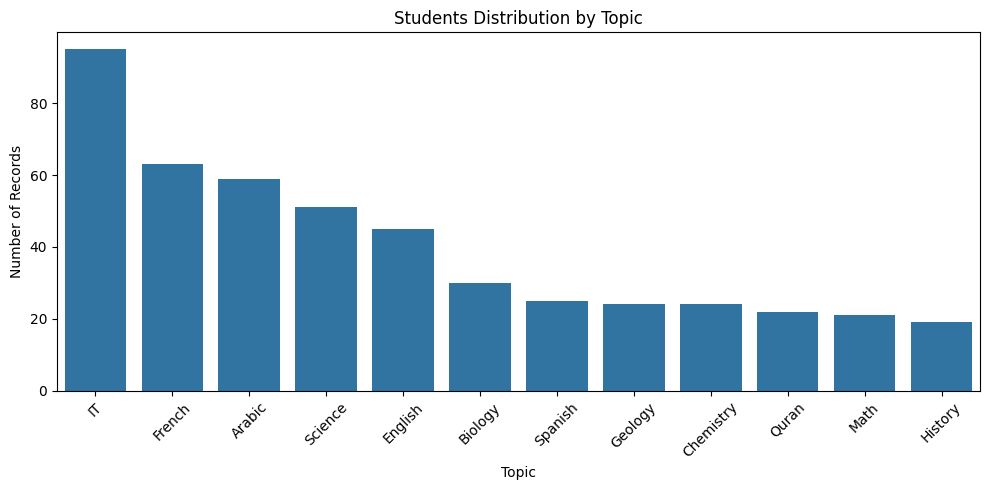

In [8]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Topic",
    order=data["Topic"].value_counts().index
)

plt.title("Students Distribution by Topic")
plt.xlabel("Topic")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


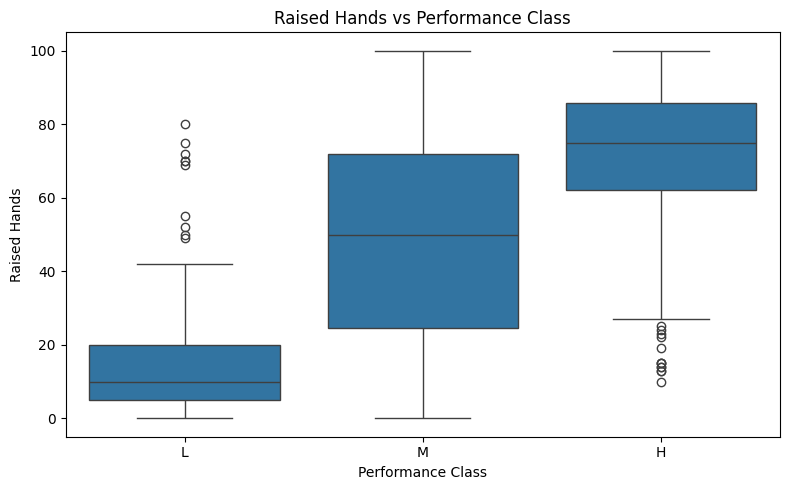

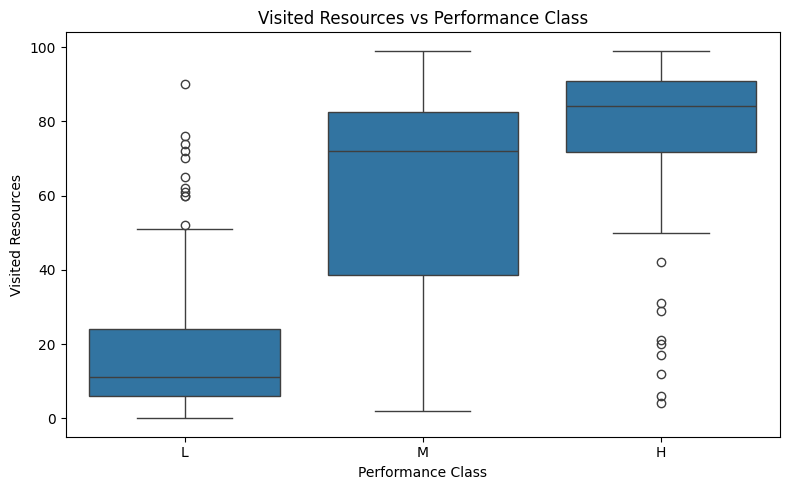

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Raised Hands vs Performance Class
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Class",
    y="raisedhands",
    order=["L", "M", "H"]
)

plt.title("Raised Hands vs Performance Class")
plt.xlabel("Performance Class")
plt.ylabel("Raised Hands")
plt.tight_layout()
plt.show()


# Graph 2: Visited Resources vs Performance Class
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Class",
    y="VisITedResources",
    order=["L", "M", "H"]
)

plt.title("Visited Resources vs Performance Class")
plt.xlabel("Performance Class")
plt.ylabel("Visited Resources")
plt.tight_layout()
plt.show()


In [12]:

# Statistical analysis of student engagement

engagement_analysis = data.groupby("Class")[
    ["raisedhands", "VisITedResources",
     "AnnouncementsView", "Discussion"]
].agg(["mean", "median", "std"]).round(2)

print("Engagement Statistics by Performance Class:")
display(engagement_analysis)


Engagement Statistics by Performance Class:


raisedhands               VisITedResources                \
             mean median    std             mean median    std   
Class                                                            
H           70.29   75.0  22.54            78.75   84.0  19.36   
L           16.84   10.0  17.30            18.42   11.0  19.32   
M           48.94   50.0  26.89            60.64   72.0  28.23   

      AnnouncementsView               Discussion                
                   mean median    std       mean median    std  
Class                                                           
H                 53.38   52.0  25.06      53.66   54.0  27.20  
L                 15.58   11.0  15.42      31.12   22.0  25.80  
M                 40.96   38.0  24.09      43.79   40.0  26.12

In [13]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Select engagement features
features = [
    "raisedhands",
    "VisITedResources",
    "AnnouncementsView",
    "Discussion"
]

X = data[features].copy()
y = data["Class"].copy()

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Performance classes:", label_encoder.classes_)
print("Feature shape:", X.shape)
print("Target shape:", y_encoded.shape)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Performance classes: ['H' 'L' 'M']
Feature shape: (478, 4)
Target shape: (478,)

Training records: 382
Testing records: 96


In [14]:

from sklearn.tree import DecisionTreeClassifier

# Create model
model = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Decision Tree training completed!")


Decision Tree training completed!


Model Accuracy: 62.5 %

Classification Report:
              precision    recall  f1-score   support

           H       0.56      0.76      0.65        29
           L       0.74      0.68      0.71        25
           M       0.62      0.50      0.55        42

    accuracy                           0.62        96
   macro avg       0.64      0.65      0.64        96
weighted avg       0.63      0.62      0.62        96



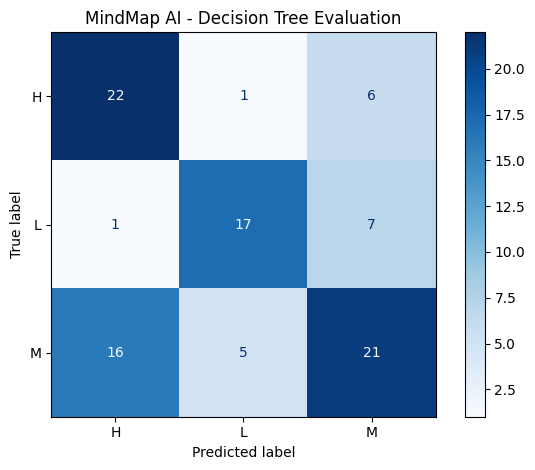

In [16]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(label_encoder.classes_))),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(label_encoder.classes_)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues")
plt.title("MindMap AI - Decision Tree Evaluation")
plt.tight_layout()
plt.show()


Feature Importance:


,Feature,Importance
1,VisITedResources,0.637159
0,raisedhands,0.213030
2,AnnouncementsView,0.111185
3,Discussion,0.038625


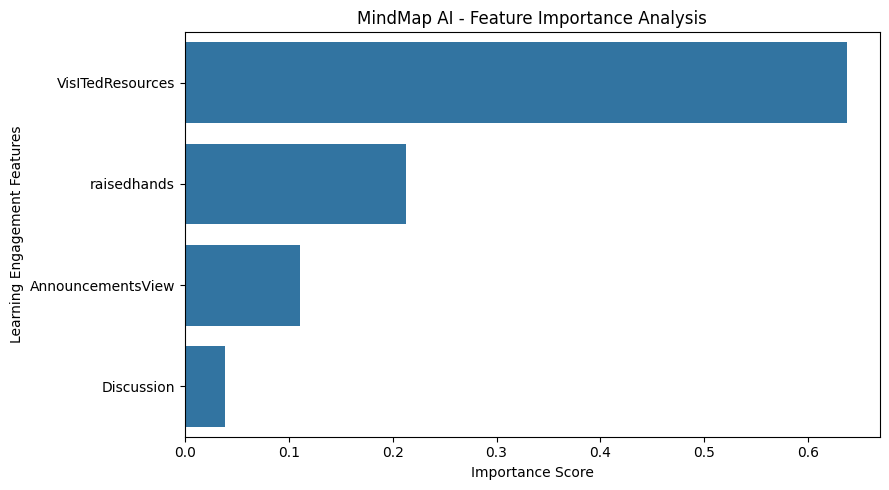

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from trained model
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance_df)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("MindMap AI - Feature Importance Analysis")
plt.xlabel("Importance Score")
plt.ylabel("Learning Engagement Features")
plt.tight_layout()
plt.show()


In [18]:

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Dummy Baseline": DummyClassifier(strategy="prior"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, clf in models.items():
    scores = cross_validate(
        clf,
        X,
        y_encoded,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        }
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean()
    })

results_df = pd.DataFrame(results)

print("5-Fold Cross-Validation Results")
display(results_df.round(3))


5-Fold Cross-Validation Results


,Model,Mean Accuracy,Mean Macro F1
0,Dummy Baseline,0.441,0.204
1,Decision Tree,0.594,0.599
2,Random Forest,0.642,0.652


In [20]:

def learning_support_recommendation(student):
    recommendations = []

    if student["raisedhands"] < 5:
        recommendations.append(
            "Encourage asking questions and interactive learning."
        )

    if student["VisITedResources"] < 5:
        recommendations.append(
            "Encourage exploring available learning resources."
        )

    if student["Discussion"] < 5:
        recommendations.append(
            "Offer a guided discussion or group activity."
        )

    if not recommendations:
        recommendations.append(
            "Continue learning and monitor future quiz results."
        )

    return recommendations


# Demonstration using one existing record
sample_student = data.iloc[0]

print("MindMap AI - Learning Support Suggestions")

for suggestion in learning_support_recommendation(sample_student):
    print("-", suggestion)


MindMap AI - Learning Support Suggestions
- Continue learning and monitor future quiz results.


In [21]:

import joblib
import os

# Create folder for saved models
os.makedirs("mindmap_model", exist_ok=True)

# Save trained model
joblib.dump(
    model,
    "mindmap_model/decision_tree_model.pkl"
)

# Save target label encoder
joblib.dump(
    label_encoder,
    "mindmap_model/label_encoder.pkl"
)

# Save feature names
joblib.dump(
    features,
    "mindmap_model/features.pkl"
)

print("MindMap AI model saved successfully!")
print("Saved files:")

print(os.listdir("mindmap_model"))


MindMap AI model saved successfully!
Saved files:
['label_encoder.pkl', 'decision_tree_model.pkl', 'features.pkl']


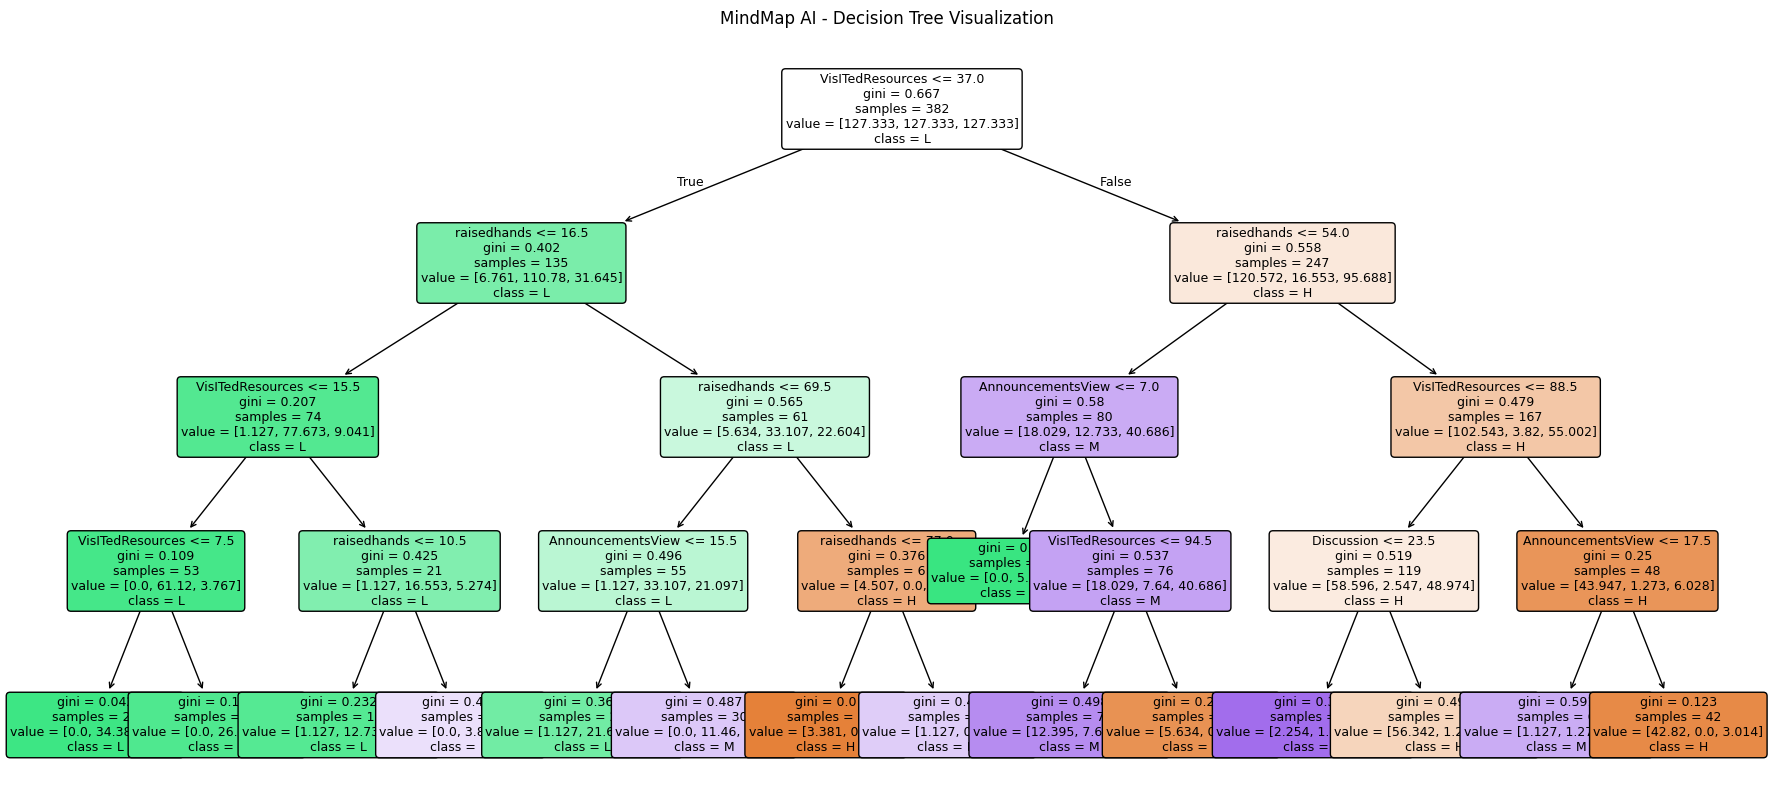

In [22]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("MindMap AI - Decision Tree Visualization")
plt.show()


In [23]:

# Example student engagement data
new_student = pd.DataFrame([{
    "raisedhands": 15,
    "VisITedResources": 20,
    "AnnouncementsView": 10,
    "Discussion": 12
}])[features]

# Predict performance
prediction_encoded = model.predict(new_student)

predicted_class = label_encoder.inverse_transform(
    prediction_encoded
)[0]

print("MindMap AI Prediction")
print("Predicted Performance:", predicted_class)


MindMap AI Prediction
Predicted Performance: M


In [24]:

import shutil
from google.colab import files

shutil.make_archive(
    "MindMap_AI_Model",
    "zip",
    "mindmap_model"
)

files.download("MindMap_AI_Model.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from google.colab import files

files.download("MindMap_AI_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>